# Qiskit Fall Fest 2026 - Vishnu Institute of Technology
## Challenge 1: Predict the Output

In this notebook, we investigate the measurement outcomes of three simple single-qubit circuits and compare our theoretical predictions with the simulation results.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

### Circuit A: Apply an X gate and measure

**Prediction:**
- The qubit starts in $|0\rangle$.
- The X gate acts like a bit-flip (NOT) gate: $X|0\rangle = |1\rangle$.
- So for 100 shots, I expect 100% of measurements to be `1` (counts: `{'1': 100}`).

In [2]:
# Circuit A
qc_A = QuantumCircuit(1, 1)
qc_A.x(0)
qc_A.measure(0, 0)

print(qc_A.draw('text'))

counts_A = simulator.run(qc_A, shots=shots).result().get_counts()
print("\nCounts:", counts_A)

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Counts: {'1': 100}


### Circuit B: Apply two X gates and measure

**Prediction:**
- Applying two X gates consecutively flips the qubit to $|1\rangle$ and then back to $|0\rangle$ ($X \cdot X = I$).
- So the qubit returns to state $|0\rangle$.
- For 100 shots, I expect 100% of measurements to be `0` (counts: `{'0': 100}`).

In [3]:
# Circuit B
qc_B = QuantumCircuit(1, 1)
qc_B.x(0)
qc_B.x(0)
qc_B.measure(0, 0)

print(qc_B.draw('text'))

counts_B = simulator.run(qc_B, shots=shots).result().get_counts()
print("\nCounts:", counts_B)

     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 

Counts: {'0': 100}


### Circuit C: Apply an H gate and measure

**Prediction:**
- The H (Hadamard) gate creates an equal superposition: $H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$.
- The probability of measuring 0 is 50%, and the probability of measuring 1 is 50%.
- For 100 shots, I expect approximately 50 counts of `0` and 50 counts of `1`.
- *Will Circuit C always produce the same measurement result?* No, because quantum measurement is probabilistic. Individual shots are random, and finite sampling variation will cause slight differences around 50/50.

In [4]:
# Circuit C
qc_C = QuantumCircuit(1, 1)
qc_C.h(0)
qc_C.measure(0, 0)

print(qc_C.draw('text'))

counts_C = simulator.run(qc_C, shots=shots).result().get_counts()
print("\nCounts:", counts_C)

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Counts: {'0': 59, '1': 41}


### Histograms of Results

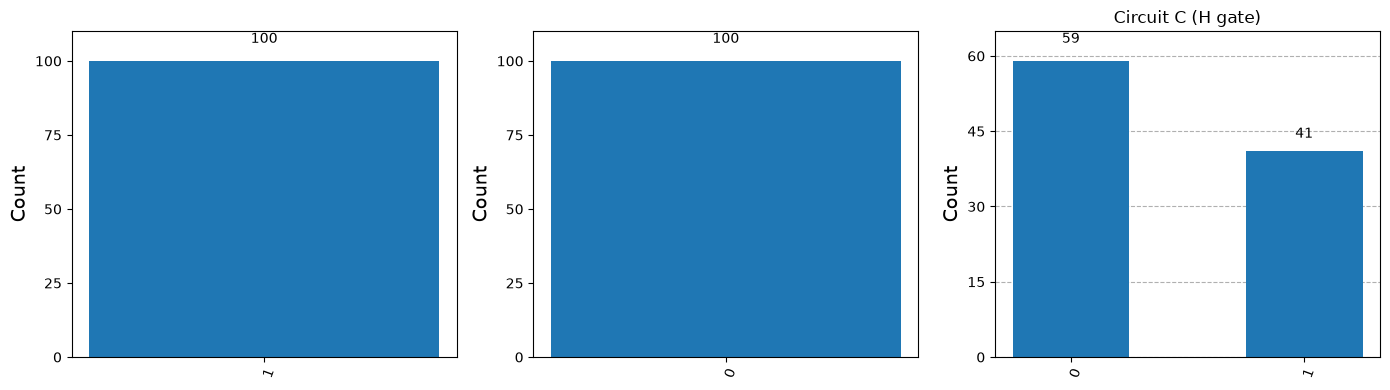

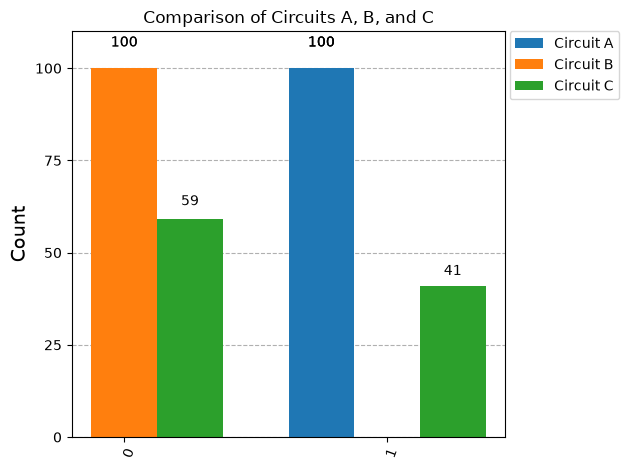

In [5]:
# Plotting histograms
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_histogram(counts_A, ax=axes[0], title="Circuit A (X gate)")
plot_histogram(counts_B, ax=axes[1], title="Circuit B (Two X gates)")
plot_histogram(counts_C, ax=axes[2], title="Circuit C (H gate)")
plt.tight_layout()
plt.show()

plot_histogram([counts_A, counts_B, counts_C], 
               legend=["Circuit A", "Circuit B", "Circuit C"], 
               title="Comparison of Circuits A, B, and C")
plt.show()

### Comparison between Predictions and Actual Results

| Circuit | Gates Applied | Expected Outcome | Actual Result (100 shots) | Observation |
| :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | X | 100% '1' | `{'1': 100}` | Exactly matches prediction. Single X flips 0 to 1 deterministically. |
| **Circuit B** | X, X | 100% '0' | `{'0': 100}` | Exactly matches prediction. Two X gates cancel out and return to 0. |
| **Circuit C** | H | ~50% '0', ~50% '1' | {'0': 59, '1': 41} | Matches prediction within expected statistical noise for 100 shots. |